# Solar filament instance segmentation: the full pipeline

This notebook runs our final pipeline **FZ_nz1** on the MAGFiLO H-alpha test frames, using only the
weights stored in `weights/`. Nothing is retrained. A **lite** mode, the earlier submission
F_full_refit_nz1 (public leaderboard 0.39), is the same pipeline without the small-filament
specialists. It is about 2.3× faster on a CPU and is selected with `configs/f_lite.yaml`.

```
frame (2048², 8-bit)
 ├─► resize 1024, per-image percentile scaling
 │    ├─► 5 × ConvNeXt-T U-Net, 8-view TTA ─► base foreground map p (upsampled to 2048²)
 │    └─► 5 × ResNet34 U-Net,  8-view TTA ─► "vote" map (features only)
 └─► native 2048, same scaling
      └─► 5 × small-filament specialist (ConvNeXt-T U-Net fine-tuned at native resolution), 8-view TTA ─► q
fused map (p + q) / 2 ─► candidates: fg ≥ 0.4, area ≥ 150 px
candidates ─► 46 features + crop-CNN score (5 × ResNet18) ─► bagged GBM ─► u = expected IoU share
           ─► keep if u ≥ 0.25 ─► expected-IoU outline ("nz1") ─► disjoint instances ─► COCO RLE rows
(lite mode: no specialists, so the map is p; it uses its own crop CNNs and GBM)
```

Sections:
1. Setup and data
2. Preprocessing on one frame
3. Training (optional, off by default)
4. Inference on the test set → `outputs/submission.csv` (FZ_nz1) and `outputs/submission_lite.csv`, each
   checked against the file we submitted
5. What the specialist adds, and post-processing explained
6. Evaluation on held-out labelled frames (FZ vs lite): PQ, small-filament recall, IoU/Dice
   distributions, 1:n / n:1 relations
7. Overlays

The saved outputs come from CPU runs (8 vCPUs). Some sections read per-frame caches; each such section
says where its frames came from.

## 1. Setup and data

```bash
pip install -r requirements.txt            # pinned versions we ran with (CPU build of PyTorch)
kaggle competitions download -c filament-segmentation-2026 -p data
unzip -q data/filament-segmentation-2026.zip -d data
# -> data/MAGFiLO_1.0_Kaggle_2026/{train,test}
```

The competition data is not part of this repository. To keep the data elsewhere, set
`FILAMENT_DATA_ROOT` to the folder that contains `train/` and `test/`.

- Default settings: `configs/fz_nz1.yaml`
- Lite mode: `configs/f_lite.yaml`
- For a quick look on a CPU, set `FILAMENT_DEMO_MAX_FRAMES=3`.

In [1]:
import json, os, sys, time, warnings
from pathlib import Path
warnings.filterwarnings('ignore', message='IProgress not found')  # tqdm notice triggered by importing timm

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
import torch
from pycocotools import mask as cm

from filament_seg.config import load_config, data_path, resolve, DEFAULT_CONFIG, LITE_CONFIG
from filament_seg.data import list_images, read_gray, model_input, normalize_image, load_ground_truth
from filament_seg.pipeline import Pipeline, predict_frames
from filament_seg.submission import write_submission, validate_submission, read_submission, sha256
from filament_seg.metrics import evaluate
from filament_seg import viz

plt.rcParams['figure.dpi'] = 80
cfg = load_config(DEFAULT_CONFIG)        # FZ_nz1
cfg_lite = load_config(LITE_CONFIG)      # F_full_refit_nz1
OUT = resolve(cfg['output']['dir']); OUT.mkdir(exist_ok=True)
test_paths = list_images(data_path(cfg, 'test_images'))
train_paths = list_images(data_path(cfg, 'train_images'))
print(f'test frames: {len(test_paths)}, labelled frames: {len(train_paths)}')
MAX_FRAMES = int(os.environ.get('FILAMENT_DEMO_MAX_FRAMES', 0)) or None
run_paths = dict(list(test_paths.items())[:MAX_FRAMES])
print(f'frames processed in this run: {len(run_paths)}')
print(f'torch {torch.__version__}, device: {"cuda" if torch.cuda.is_available() else "cpu"}, CPU threads: {torch.get_num_threads()}')

manifest = json.loads((resolve(cfg['weights']['dir'])/'manifest.json').read_text())
files = sorted(resolve(cfg['weights']['dir']).iterdir())
sizes = {f.name: f.stat().st_size/1e6 for f in files}
print(f'weights/: {len(files)} files, {sum(sizes.values()):.0f} MB, largest {max(sizes, key=sizes.get)} ({max(sizes.values()):.1f} MB)')
used = lambda c: set(c['weights']['segmenters']+c['weights']['voters']+c['weights'].get('specialists', [])+c['weights']['crop_cnns'])
for name, c in [('FZ_nz1 (default)', cfg), ('lite', cfg_lite)]:
    mb = sum(sizes[f] for n in used(c) for f in manifest[n]['files'])+sizes[c['weights']['gbm']]
    print(f'  {name:17s}: {len(used(c))} networks + GBM, {mb:.0f} MB')
for name, entry in manifest.items():
    if name.startswith(('cnx', 'spec', 'r34')):
        t = entry.get('training', {})
        print(f"  {name:>11}: {entry['architecture']}, fold {entry['fold']}, input {t.get('side', 1024)}, "
              f"selected epoch {t.get('selected_epoch')}, {len(entry['files'])} shards")

test frames: 180, labelled frames: 707
frames processed in this run: 180
torch 2.11.0+cpu, device: cpu, CPU threads: 8
weights/: 45 files, 2084 MB, largest r34_fold0.part1of2.safetensors (85.2 MB)
  FZ_nz1 (default) : 20 networks + GBM, 1904 MB
  lite             : 15 networks + GBM, 1264 MB
    cnx_fold0: ConvNeXtUNet, fold 0, input 1024, selected epoch 68, 2 shards
    cnx_fold1: ConvNeXtUNet, fold 1, input 1024, selected epoch 89, 2 shards
    cnx_fold2: ConvNeXtUNet, fold 2, input 1024, selected epoch 94, 2 shards
    cnx_fold3: ConvNeXtUNet, fold 3, input 1024, selected epoch 91, 2 shards
    cnx_fold4: ConvNeXtUNet, fold 4, input 1024, selected epoch 74, 2 shards
    r34_fold0: ResNet34UNet, fold 0, input 1024, selected epoch 11, 2 shards
    r34_fold1: ResNet34UNet, fold 1, input 1024, selected epoch 7, 2 shards
    r34_fold2: ResNet34UNet, fold 2, input 1024, selected epoch 11, 2 shards
    r34_fold3: ResNet34UNet, fold 3, input 1024, selected epoch 10, 2 shards
    r34_fold4: 

## 2. Preprocessing on one frame

Inference uses only the test frame itself. The frame is converted to 8-bit grayscale and rescaled
per image: the 1st/99th intensity percentiles inside a central disk (radius 0.45 of the frame) map
to 0 and 1, values are clipped and centred as (v − 0.5)/0.25. The base networks see the frame
resized to 1024 with bilinear resampling. The specialists see it at its native 2048, where faint,
thin filaments are still a few pixels wide. No dataset statistics, dates or metadata are used.

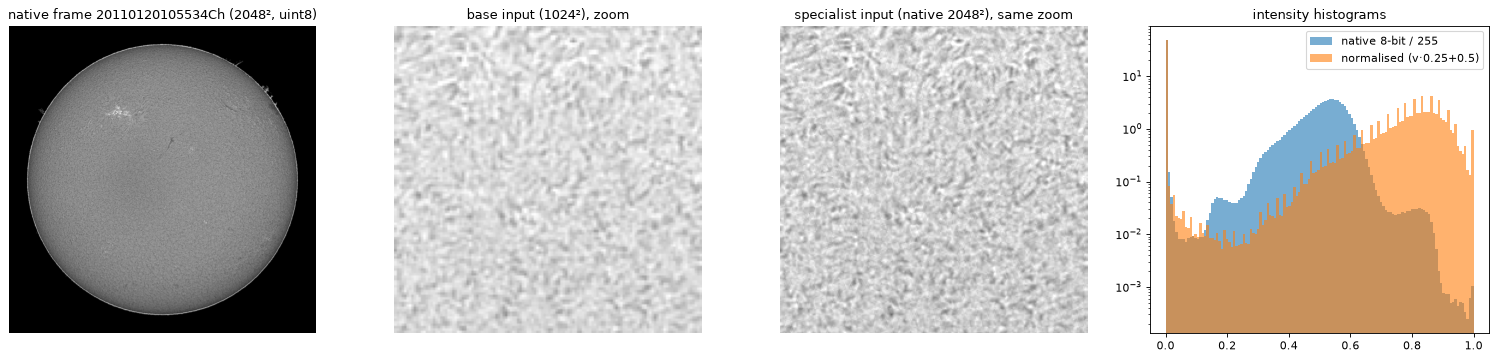

input range [-2.00, 2.00], mean -0.06


In [2]:
key = sorted(test_paths)[0]
gray = read_gray(test_paths[key])
x = model_input(test_paths[key], cfg['inference']['side'])
xn = normalize_image(gray)
crop = (slice(700, 956), slice(700, 956))
fig, ax = plt.subplots(1, 4, figsize=(19, 4.6))
ax[0].imshow(gray, cmap='gray'); ax[0].set_title(f'native frame {key} (2048², uint8)'); ax[0].axis('off')
ax[1].imshow(x[350:478, 350:478], cmap='gray', vmin=-2, vmax=2); ax[1].set_title('base input (1024²), zoom'); ax[1].axis('off')
ax[2].imshow(xn[crop], cmap='gray', vmin=-2, vmax=2); ax[2].set_title('specialist input (native 2048²), same zoom'); ax[2].axis('off')
ax[3].hist(gray.ravel()/255, 128, alpha=.6, density=True, label='native 8-bit / 255')
ax[3].hist(((x*.25)+.5).ravel(), 128, alpha=.6, density=True, label='normalised (v·0.25+0.5)')
ax[3].set_yscale('log'); ax[3].legend(); ax[3].set_title('intensity histograms')
plt.tight_layout(); plt.show()
print(f'input range [{x.min():.2f}, {x.max():.2f}], mean {x.mean():.2f}')

## 3. Training (optional; not run by default)

The released weights were trained on GPUs with the scripts in `train/`; `train/README.md` has the
details. All 707 labelled frames were split into 5 calendar-month folds (`configs/folds_full.json`).
Fold *k*'s networks never saw fold *k*'s frames, which is what makes out-of-fold verifier training
possible.

1. `prepare_data.py`: model-side image caches and per-annotator soft targets (768 and 1024)
2. `train_convnext_unet.py`: 5 ConvNeXt-T U-Nets, 120 epochs each (about 1.5 h per fold on an H200)
3. `train_r34_unet.py`: 5 ResNet34 U-Nets, 45 + 12 epochs (about 1 h per fold)
4. `train_specialist.py`: native-resolution caches, then each ConvNeXt fold fine-tuned for 12 epochs
   on 768-px native crops with a small-object-weighted loss (about 15 min per fold on an A100)
5. `build_verifier_data.py`: out-of-fold maps (fused for FZ) → candidates, 46 features, IoU targets, crops
6. `train_crop_cnn.py`: 5 crop CNNs plus out-of-fold scores
7. `train_gbm.py`: 100 bagged GBMs, plus the fold-0-excluded copies used in section 6
8. `export_weights.py`: shard the checkpoints into `weights/`

Steps 5–7 run once per mode. `RUN_TRAINING = True` runs the FZ chain. `SMOKE = True` runs every
script on a handful of frames for one epoch, a few minutes on a CPU, to check that it works.

In [3]:
RUN_TRAINING = False
SMOKE = True
work = REPO/'work'/('smoke' if SMOKE else 'full')
smoke = ['--smoke'] if SMOKE else []
py = sys.executable
commands = [[py, 'train/prepare_data.py', '--out', f'{work}/prepared', *smoke],
            [py, 'train/train_specialist.py', 'prep', '--out', f'{work}/native', *smoke]]
for k in range(1 if SMOKE else 5):
    commands += [[py, 'train/train_convnext_unet.py', '--cache', f'{work}/prepared/1024', '--fold', str(k),
                  '--out', f'{work}/runs/cnx_fold{k}', *smoke],
                 [py, 'train/train_r34_unet.py', '--cache768', f'{work}/prepared/768', '--cache1024', f'{work}/prepared/1024',
                  '--fold', str(k), '--out', f'{work}/runs/r34_fold{k}', *smoke],
                 [py, 'train/train_specialist.py', 'train', '--cache', f'{work}/native', '--fold', str(k),
                  '--init', f'{work}/runs/cnx_fold{k}/best.pt', '--out', f'{work}/runs/spec_fold{k}', *smoke]]
commands += [[py, 'train/build_verifier_data.py', '--config', 'configs/fz_nz1.yaml', '--runs', f'{work}/runs',
              '--out', f'{work}/verifier_data_fz.npz', *(['--smoke', '--from-weights'] if SMOKE else [])],
             [py, 'train/train_crop_cnn.py', '--data', f'{work}/verifier_data_fz.npz', '--out', f'{work}/runs/crop_cnn_fz', *smoke],
             [py, 'train/train_gbm.py', '--data', f'{work}/verifier_data_fz.npz', '--cnn', f'{work}/runs/crop_cnn_fz/cnn_oof_scores.npz',
              '--out', f'{work}/runs/verifier_gbm_fz.pkl', *smoke]]
for c in commands:
    print(' '.join(str(Path(a).relative_to(REPO)) if str(a).startswith(str(REPO)) else str(a) for a in c[1:]))
if RUN_TRAINING:
    import subprocess
    for c in commands:
        subprocess.run(c, cwd=REPO, check=True)

train/prepare_data.py --out work/smoke/prepared --smoke
train/train_specialist.py prep --out work/smoke/native --smoke
train/train_convnext_unet.py --cache work/smoke/prepared/1024 --fold 0 --out work/smoke/runs/cnx_fold0 --smoke
train/train_r34_unet.py --cache768 work/smoke/prepared/768 --cache1024 work/smoke/prepared/1024 --fold 0 --out work/smoke/runs/r34_fold0 --smoke
train/train_specialist.py train --cache work/smoke/native --fold 0 --init work/smoke/runs/cnx_fold0/best.pt --out work/smoke/runs/spec_fold0 --smoke
train/build_verifier_data.py --config configs/fz_nz1.yaml --runs work/smoke/runs --out work/smoke/verifier_data_fz.npz --smoke --from-weights
train/train_crop_cnn.py --data work/smoke/verifier_data_fz.npz --out work/smoke/runs/crop_cnn_fz --smoke
train/train_gbm.py --data work/smoke/verifier_data_fz.npz --cnn work/smoke/runs/crop_cnn_fz/cnn_oof_scores.npz --out work/smoke/runs/verifier_gbm_fz.pkl --smoke


## 4. Inference on the test set → `submission.csv`

Per frame, FZ_nz1 runs:
- 5 ConvNeXt + 5 ResNet34 networks × 8 views at 1024²
- 5 specialists × 8 views at 2048²
- then candidates, features, crop CNNs, GBM and post-processing

Results are cached per frame in `outputs/frames_test_<mode>/`, so an interrupted run resumes. Each CSV
is compared with the file we submitted (`reference/`).

**Where the saved FZ frames come from.** A CPU-only end-to-end run of all 180 frames takes about
12 h; we did not run it for this notebook. The cache holds two kinds of frames:
- 10 frames, every 18th, computed end to end on the CPU by this code (`predict_frames`)
- the other 170 from the probability maps saved by the GPU run that produced the submission, passed
  through this repository's own post-network code (`Pipeline.process`)

Feeding all 180 saved GPU maps through that code reproduces the submitted CSV byte for byte. The
cell prints how many frames came from each source.

**Lite mode** is checked over all 180 frames, all computed end to end on a CPU in an earlier run of
this notebook. That run shared the machine with other jobs, so its stored timings include
contention. On the unshared machine the lite median was 104 s per frame.

In [4]:
def run_mode(c, cache_name, csv_name, ref_name):
    t0 = time.perf_counter()
    pipe = Pipeline(c)
    print(f'{c["name"]}: models loaded in {time.perf_counter()-t0:.1f} s on {pipe.predictor.device}')
    frames = predict_frames(pipe, run_paths, OUT/cache_name, log_every=60)
    csv_path = OUT/csv_name
    digest = write_submission({k: v['rles'] for k, v in frames.items()}, csv_path)
    print(validate_submission(csv_path, test_paths))
    cpu = [k for k, f in frames.items() if 'maps' not in f]
    print(f'frames computed end to end by this code on CPU: {len(cpu)}; from saved GPU-run maps: {len(frames)-len(cpu)}')
    if cpu:
        sec = {s: np.array([frames[k]['seconds'][s] for k in cpu]) for s in frames[cpu[0]]['seconds']}
        print('CPU seconds per frame (median): ' + ', '.join(f'{s} {np.median(v):.1f}' for s, v in sec.items()))
    ref, new = read_submission(REPO/'reference'/ref_name), read_submission(csv_path)
    print('sha256 submitted :', sha256(REPO/'reference'/ref_name))
    print('sha256 reproduced:', digest, '-> IDENTICAL FILE' if digest == sha256(REPO/'reference'/ref_name) else '-> files differ')
    dec = lambda r: cm.decode({'size': [2048, 2048], 'counts': r.encode()}).astype(bool)
    for label, keys in [('all frames', list(run_paths)), ('CPU end-to-end frames', cpu)]:
        if not keys:
            continue
        same = sum(ref.get(k, []) == new.get(k, []) for k in keys)
        counts = all(len(ref.get(k, [])) == len(new.get(k, [])) for k in keys)
        pairs = [(x, y) for k in keys for x, y in zip(ref.get(k, []), new.get(k, [])) if x != y]
        px = [int((dec(x) ^ dec(y)).sum()) for x, y in pairs]
        n_ref = sum(len(ref.get(k, [])) for k in keys)
        print(f'  {label}: {same}/{len(keys)} frames identical; same mask counts: {counts}; {n_ref} submitted masks, '
              f'{len(pairs)} differ by {sum(px)} pixels in total (max {max(px, default=0)} per mask)')
    del pipe
    return frames

frames = run_mode(cfg, 'frames_test_FZ_nz1', 'submission.csv', 'submission_FZ_nz1.csv')

FZ_nz1: models loaded in 61.6 s on cpu
60/180 frames (0 computed now, 60 from the cache), 0 s elapsed


120/180 frames (0 computed now, 120 from the cache), 0 s elapsed


180/180 frames (0 computed now, 180 from the cache), 0 s elapsed


{'rows': 1169, 'images_with_instances': 177, 'images_without_instances': 3, 'disjoint': True}
frames computed end to end by this code on CPU: 10; from saved GPU-run maps: 170
CPU seconds per frame (median): networks 236.3, candidates_features 0.2, verifier 1.1, postprocess_encode 0.4, total 237.8
sha256 submitted : 8f07cb44cbecf1371e9fcdba5334addcdfa7de02e462a224ba927c5ca56b3410
sha256 reproduced: 9b8d784f9c02bc64361b1052ef7d164d830095180857db99d9e1e3c35a3ca2d0 -> files differ


  all frames: 171/180 frames identical; same mask counts: True; 1169 submitted masks, 29 differ by 45 pixels in total (max 4 per mask)


  CPU end-to-end frames: 1/10 frames identical; same mask counts: True; 69 submitted masks, 29 differ by 45 pixels in total (max 4 per mask)


In [5]:
frames_lite = run_mode(cfg_lite, 'frames_test_lite', 'submission_lite.csv', 'submission_F_full_refit_nz1.csv')

F_full_refit_nz1: models loaded in 24.0 s on cpu
60/180 frames (0 computed now, 60 from the cache), 0 s elapsed


120/180 frames (0 computed now, 120 from the cache), 0 s elapsed


180/180 frames (0 computed now, 180 from the cache), 0 s elapsed


{'rows': 1088, 'images_with_instances': 177, 'images_without_instances': 3, 'disjoint': True}
frames computed end to end by this code on CPU: 180; from saved GPU-run maps: 0
CPU seconds per frame (median): networks 155.0, candidates_features 0.2, verifier 2.9, postprocess_encode 0.4, total 159.6
sha256 submitted : df7e63f7bc297d511ae1fce05bc62da17b69bb4ec6845d9b3bb96fbafd476c5e
sha256 reproduced: ac0abef8c9e49e7ca7a6565947490c4403f0fb813e01aaf5d0ab5a9d11fa510a -> files differ


  all frames: 144/180 frames identical; same mask counts: True; 1088 submitted masks, 42 differ by 44 pixels in total (max 2 per mask)


  CPU end-to-end frames: 144/180 frames identical; same mask counts: True; 1088 submitted masks, 42 differ by 44 pixels in total (max 2 per mask)


## 5. What the specialist adds, and post-processing explained

The base networks work at 1024², half the native resolution. Faint, thin, small filaments often stay
below the 0.4 threshold there. The specialist sees the native pixels and was trained with extra
weight on small filaments. Averaging its map with the base map lifts many of these filaments over the
threshold and also sharpens their extent.

The fused map is thresholded at 0.4 and split into 8-connected **candidates** (≥ 150 px, holes filled).
Each candidate gets 46 features:
- shape, probabilities and photometry
- agreement between the TTA and single-view maps
- position on the disk and neighbouring candidates
- votes of the ResNet34 ensemble

It also gets a crop-CNN score. A bagged GBM, retrained on fused-map candidates, predicts **u**: the
candidate's expected matched IoU averaged over annotators (0 if unmatched), i.e. its share of the PQ
numerator. Keeping a candidate helps PQ when u exceeds about PQ/2, hence **τ = 0.25**.

Kept candidates are then re-outlined (**nz1**). Among the nested threshold levels 0.25 … 0.70 of the
same map, each candidate takes the level with the highest *expected* IoU, treating the map as the
probability that an annotator includes a pixel. Growth is confined to the candidate's Voronoi
territory (≤ 16 px), so instances stay disjoint. The steps are listed in the config
(`postprocess.steps`) and can be extended.

20131027185354Bh: 20 candidates, kept 15 (lite kept 11 masks)  (728 s for this frame on cpu)


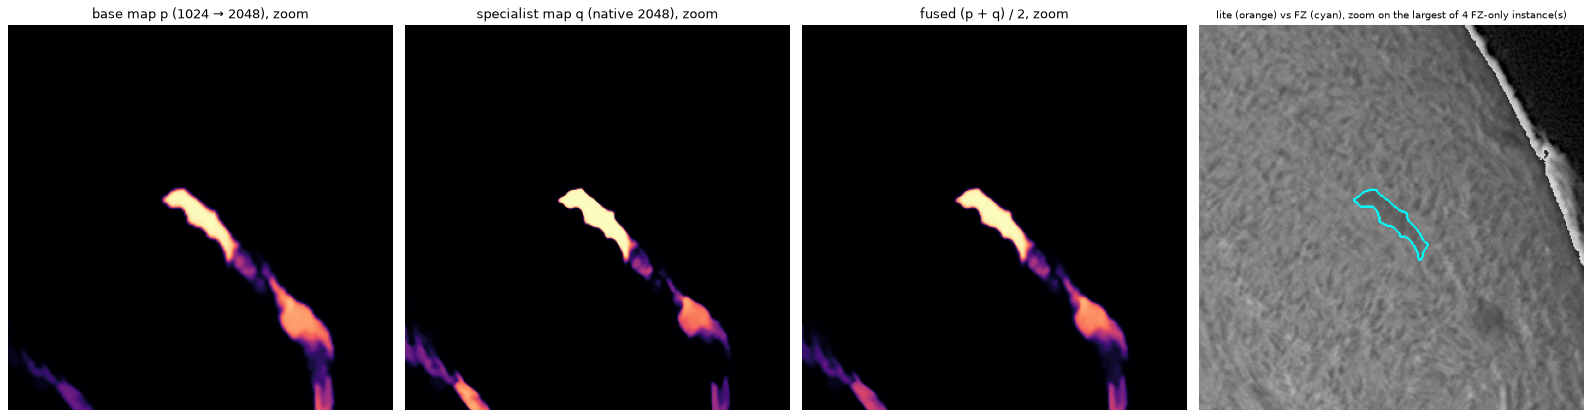

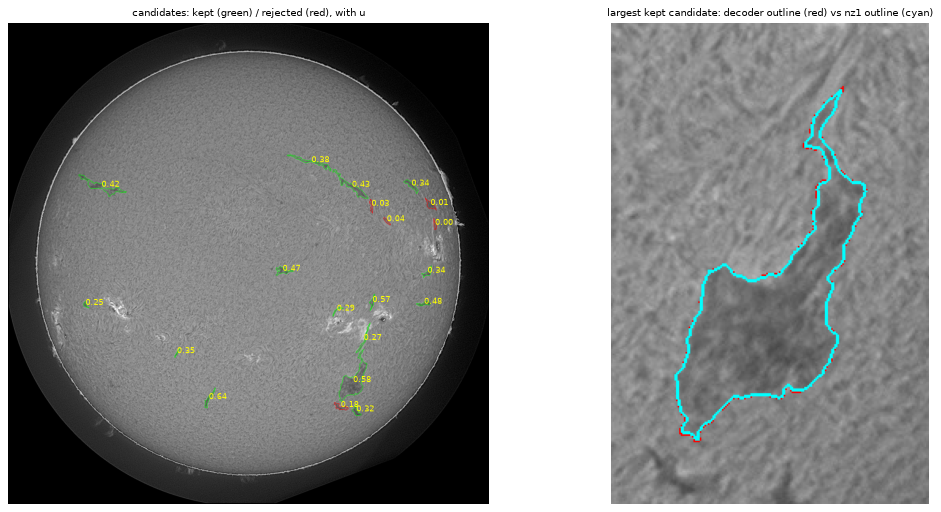

In [6]:
# rerun one test frame in memory (FZ) and show base, specialist and fused maps
key = max(frames, key=lambda k: len(frames[k]['rles']) - len(frames_lite.get(k, {'rles': []})['rles']))
pipe = Pipeline(cfg)
t0 = time.perf_counter()
gray = read_gray(test_paths[key])
from filament_seg.inference import fuse
pred = pipe.predictor
specialists, pred.specialists = pred.specialists, []
base = pred(test_paths[key])                      # base networks only (= lite maps)
pred.specialists = specialists
q_single, q_decode = pred.specialist_maps(gray)   # the 5 specialists at native resolution
w = pred.fusion_weight
maps = {'decode': fuse(base['decode'], q_decode, w), 'single': fuse(base['single'], q_single, w), 'vote': base['vote']}
res = pipe.process(key, gray, maps)               # identical to pipe(key, path), split up to show the maps
print(f'{key}: {len(res.u)} candidates, kept {res.keep.sum()} (lite kept {len(frames_lite[key]["rles"])} masks)  '
      f'({time.perf_counter()-t0:.0f} s for this frame on {pred.device})')
base_fg = base['decode'][0]
lite_lab = np.zeros((2048, 2048), np.int32)
for i, r in enumerate(frames_lite[key]['rles'], 1):
    lite_lab[cm.decode({'size': [2048, 2048], 'counts': r.encode()}).astype(bool)] = i
new_only = [i for i in range(1, res.instances.max()+1) if not lite_lab[res.instances == i].any()]
big = max(new_only, key=lambda i: (res.instances == i).sum()) if new_only else None
c = np.argwhere(res.instances == big).mean(0).astype(int) if new_only else np.array([1024, 1024])
zoom = (slice(max(c[0]-160, 0), c[0]+160), slice(max(c[1]-160, 0), c[1]+160))
fig, ax = plt.subplots(1, 4, figsize=(20, 5.4))
for a, (m, t) in zip(ax[:3], [(base_fg, 'base map p (1024 → 2048)'), (q_decode, 'specialist map q (native 2048)'),
                              (maps['decode'][0], 'fused (p + q) / 2')]):
    a.imshow(m[zoom], cmap='magma', vmin=0, vmax=1); a.set_title(t + ', zoom'); a.axis('off')
viz.overlay(gray, [(lite_lab, (1, .5, 0)), (res.instances, (0, 1, 1))], ax[3],
            f'lite (orange) vs FZ (cyan), zoom on the largest of {len(new_only)} FZ-only instance(s)', crop=zoom)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
kept = np.where(np.isin(res.candidates, np.flatnonzero(res.keep)+1), res.candidates, 0)
rejected = np.where(np.isin(res.candidates, np.flatnonzero(~res.keep)+1), res.candidates, 0)
viz.overlay(gray, [(kept, (0, 1, 0)), (rejected, (1, 0, 0))], ax[0], 'candidates: kept (green) / rejected (red), with u')
from scipy import ndimage as ndi
for j, cc in enumerate(ndi.center_of_mass(res.candidates > 0, res.candidates, range(1, len(res.u)+1))):
    ax[0].text(cc[1], cc[0], f'{res.u[j]:.2f}', color='yellow', fontsize=7)
j = int(np.argmax(np.where(res.keep, [(res.candidates == i+1).sum() for i in range(len(res.u))], 0)))
ys, xs = np.nonzero(res.candidates == j+1); pad = 40
crop = (slice(max(ys.min()-pad, 0), ys.max()+pad), slice(max(xs.min()-pad, 0), xs.max()+pad))
viz.overlay(gray, [((res.candidates == j+1).astype(int), (1, 0, 0)), ((res.instances == int(np.cumsum(res.keep)[j])).astype(int), (0, 1, 1))],
            ax[1], 'largest kept candidate: decoder outline (red) vs nz1 outline (cyan)', crop=crop)
plt.tight_layout(); plt.show()
del pipe

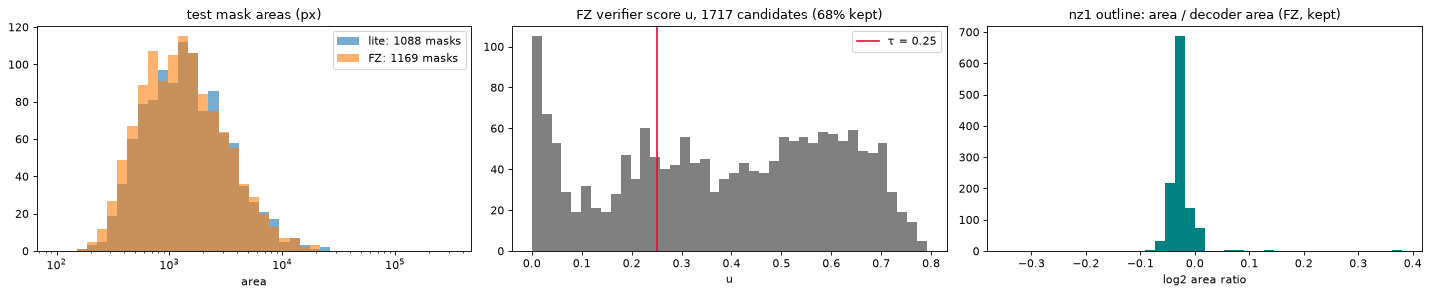

masks < 1000 px: lite 391, FZ 464;  nz1: median area ratio 0.982, grown 1%, shrunk 92%


In [7]:
# test-set statistics (FZ vs lite): masks per frame, mask sizes, verifier scores, outline change
area = lambda rles: np.asarray(cm.area([{'size': [2048, 2048], 'counts': r.encode()} for r in rles])) if rles else np.zeros(0)
a_fz = np.concatenate([area(f['rles']) for f in frames.values()]); a_lite = np.concatenate([area(f['rles']) for f in frames_lite.values()])
u_all = np.concatenate([f['u'] for f in frames.values()]); keep_all = np.concatenate([f['keep'] for f in frames.values()]).astype(bool)
ratio = np.concatenate([area(f['rles'])/area([r for r, k in zip(f['candidate_rles'], f['keep']) if k])
                        for f in frames.values() if f['rles']])
fig, ax = plt.subplots(1, 3, figsize=(18, 3.8))
bins = np.logspace(2, 5.5, 40)
ax[0].hist(a_lite, bins, alpha=.6, label=f'lite: {len(a_lite)} masks'); ax[0].hist(a_fz, bins, alpha=.6, label=f'FZ: {len(a_fz)} masks')
ax[0].set_xscale('log'); ax[0].set(title='test mask areas (px)', xlabel='area'); ax[0].legend()
ax[1].hist(u_all, 40, color='gray'); ax[1].axvline(cfg['verifier']['tau'], color='crimson', label='τ = 0.25')
ax[1].set(title=f'FZ verifier score u, {len(u_all)} candidates ({keep_all.mean():.0%} kept)', xlabel='u'); ax[1].legend()
ax[2].hist(np.log2(ratio), 40, color='teal'); ax[2].set(title='nz1 outline: area / decoder area (FZ, kept)', xlabel='log2 area ratio')
plt.tight_layout(); plt.show()
print(f'masks < 1000 px: lite {(a_lite < 1000).sum()}, FZ {(a_fz < 1000).sum()};  '
      f'nz1: median area ratio {np.median(ratio):.3f}, grown {np.mean(ratio > 1):.0%}, shrunk {np.mean(ratio < 1):.0%}')

## 6. Evaluation on held-out labelled frames (FZ vs lite)

The submitted networks were refit on all 707 labelled frames, so no labelled frame is unseen by the
full ensembles. For an honest check we use the **142 frames of fold 0** and only models that never
saw them:
- **FZ:** ConvNeXt fold 0, specialist fold 0, ResNet34 fold 0, FZ crop-CNN fold 0, and a GBM refit
  without fold 0's candidates (`verifier_gbm_fz_without_fold0.pkl.gz`)
- **lite:** the same without the specialist, with the lite crop-CNN fold 0 and
  `verifier_gbm_without_fold0.pkl.gz`

These are single-fold pipelines, so they slightly understate the 5-model ensembles.

**Where the frames come from.** All held-out frames were computed end to end on a CPU by this code;
this run reads them from the per-frame caches. The FZ cache was filled by worker processes calling
`predict_frames` in parallel; the lite cache comes from the earlier run of this notebook.

The metric follows the host's self-evaluation notebook exactly. Every annotator's record of a frame is
scored separately against the same predictions, TP = pairs with IoU > 0.5, and PQ is pooled over all
records. Three stages are scored:
- all candidates
- after the verifier
- after the nz1 outline (the final output)

In [8]:
folds = json.loads(resolve(cfg['data']['folds']).read_text())['folds']
held = sorted(folds[0]['heldout_sources'])[:MAX_FRAMES]
held_paths = {k: train_paths[k] for k in held}
gt = load_ground_truth(data_path(cfg, 'train_annotations'), set(held))
print(f'{len(held)} frames, {sum(map(len, gt.values()))} annotator records, '
      f'{sum(len(r) for v in gt.values() for _, r in v)} GT filaments')
setups = {'FZ': (cfg, dict(segmenters=['cnx_fold0'], specialists=['spec_fold0'], voters=['r34_fold0'],
                           crop_cnns=['crop_cnn_fz_fold0'], gbm='verifier_gbm_fz_without_fold0.pkl.gz'), 'frames_heldout_fold0_FZ_nz1'),
          'lite': (cfg_lite, dict(segmenters=['cnx_fold0'], voters=['r34_fold0'], crop_cnns=['crop_cnn_fold0'],
                                  gbm='verifier_gbm_without_fold0.pkl.gz'), 'frames_heldout_fold0_lite')}
held_frames, results = {}, {}
for mode, (c, models, cache) in setups.items():
    held_frames[mode] = predict_frames(Pipeline(c, **models), held_paths, OUT/cache, log_every=71)
    hf = held_frames[mode]
    stages = {'all candidates': {k: f['candidate_rles'] for k, f in hf.items()},
              'verifier': {k: [r for r, kp in zip(f['candidate_rles'], f['keep']) if kp] for k, f in hf.items()},
              'verifier + nz1 (final)': {k: f['rles'] for k, f in hf.items()}}
    results[mode] = {name: evaluate(gt, pred) for name, pred in stages.items()}
    for name, r in results[mode].items():
        o = r['overall']
        print(f"{mode:4s} {name:24s} PQ {o['pq']:.4f}  SQ {o['sq']:.4f}  RQ {o['rq']:.4f}  TP {o['tp']:4d}  FP {o['fp']:4d}  FN {o['fn']:4d}")
for mode in results:
    r = results[mode]['verifier + nz1 (final)']; small = r['gt_area'] < 1000
    print(f"{mode:4s} recall of GT filaments < 1000 px: {r['gt_hit'][small].mean():.3f} ({small.sum()} GT);  "
          f">= 1000 px: {r['gt_hit'][~small].mean():.3f}")
d = results['FZ']['verifier + nz1 (final)']['overall']['pq'] - results['lite']['verifier + nz1 (final)']['overall']['pq']
print(f'FZ - lite, final PQ on these 142 frames: {d:+.4f}')

142 frames, 236 annotator records, 1633 GT filaments


71/142 frames (0 computed now, 71 from the cache), 0 s elapsed


142/142 frames (0 computed now, 142 from the cache), 0 s elapsed


FZ   all candidates           PQ 0.4359  SQ 0.6838  RQ 0.6374  TP 1185  FP  900  FN  448
FZ   verifier                 PQ 0.4811  SQ 0.6867  RQ 0.7005  TP 1097  FP  402  FN  536
FZ   verifier + nz1 (final)   PQ 0.4830  SQ 0.6877  RQ 0.7024  TP 1100  FP  399  FN  533


71/142 frames (0 computed now, 71 from the cache), 0 s elapsed


142/142 frames (0 computed now, 142 from the cache), 0 s elapsed


lite all candidates           PQ 0.4239  SQ 0.6751  RQ 0.6279  TP 1118  FP  810  FN  515
lite verifier                 PQ 0.4611  SQ 0.6791  RQ 0.6790  TP 1028  FP  367  FN  605
lite verifier + nz1 (final)   PQ 0.4641  SQ 0.6808  RQ 0.6816  TP 1032  FP  363  FN  601
FZ   recall of GT filaments < 1000 px: 0.595 (696 GT);  >= 1000 px: 0.732
lite recall of GT filaments < 1000 px: 0.526 (696 GT);  >= 1000 px: 0.711
FZ - lite, final PQ on these 142 frames: +0.0190


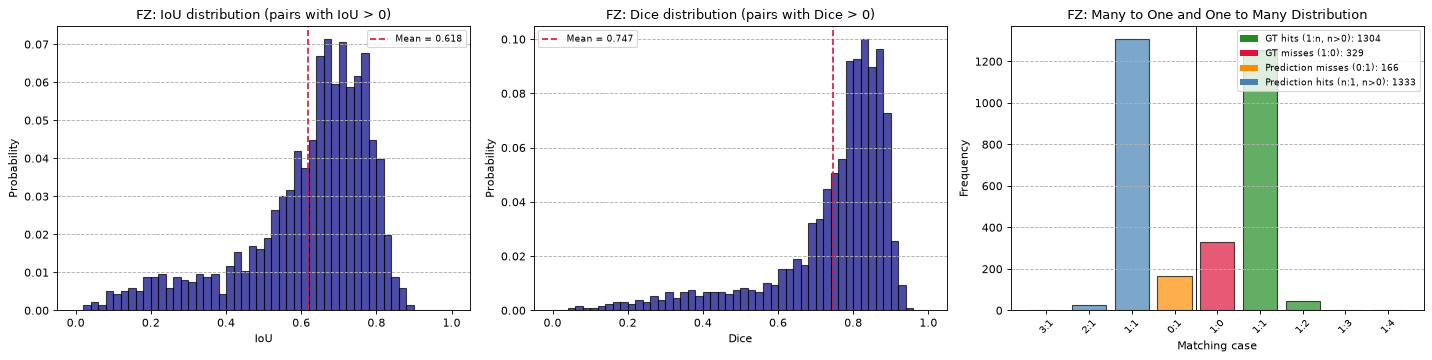

FZ   GT -> #overlapping predictions: {0: 329, 1: 1253, 2: 47, 3: 3, 4: 1} | prediction -> #overlapping GT: {0: 166, 1: 1307, 2: 25, 3: 1}
lite GT -> #overlapping predictions: {0: 378, 1: 1215, 2: 37, 3: 3} | prediction -> #overlapping GT: {0: 133, 1: 1226, 2: 36}


In [9]:
final = results['FZ']['verifier + nz1 (final)']
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
viz.plot_distribution(final['positive_ious'], 'FZ: IoU distribution (pairs with IoU > 0)', 'IoU', ax[0])
viz.plot_distribution(final['positive_dices'], 'FZ: Dice distribution (pairs with Dice > 0)', 'Dice', ax[1])
viz.plot_relations(final['gt_degree'], final['pred_degree'], ax[2], 'FZ: Many to One and One to Many Distribution')
plt.tight_layout(); plt.show()
for mode in results:
    r = results[mode]['verifier + nz1 (final)']
    print(f'{mode:4s} GT -> #overlapping predictions:', dict(sorted(r['gt_degree'].items())),
          '| prediction -> #overlapping GT:', dict(sorted(r['pred_degree'].items())))

## 7. Overlays

Held-out frames: every annotator's filaments (one colour per annotator), our FZ instances (cyan) and
the lite instances (white, drawn underneath the cyan FZ outlines, so white shows only where the two differ). Then two
test frames with our FZ predictions only (no labels exist for them). Each row shows the full frame and
a zoom.

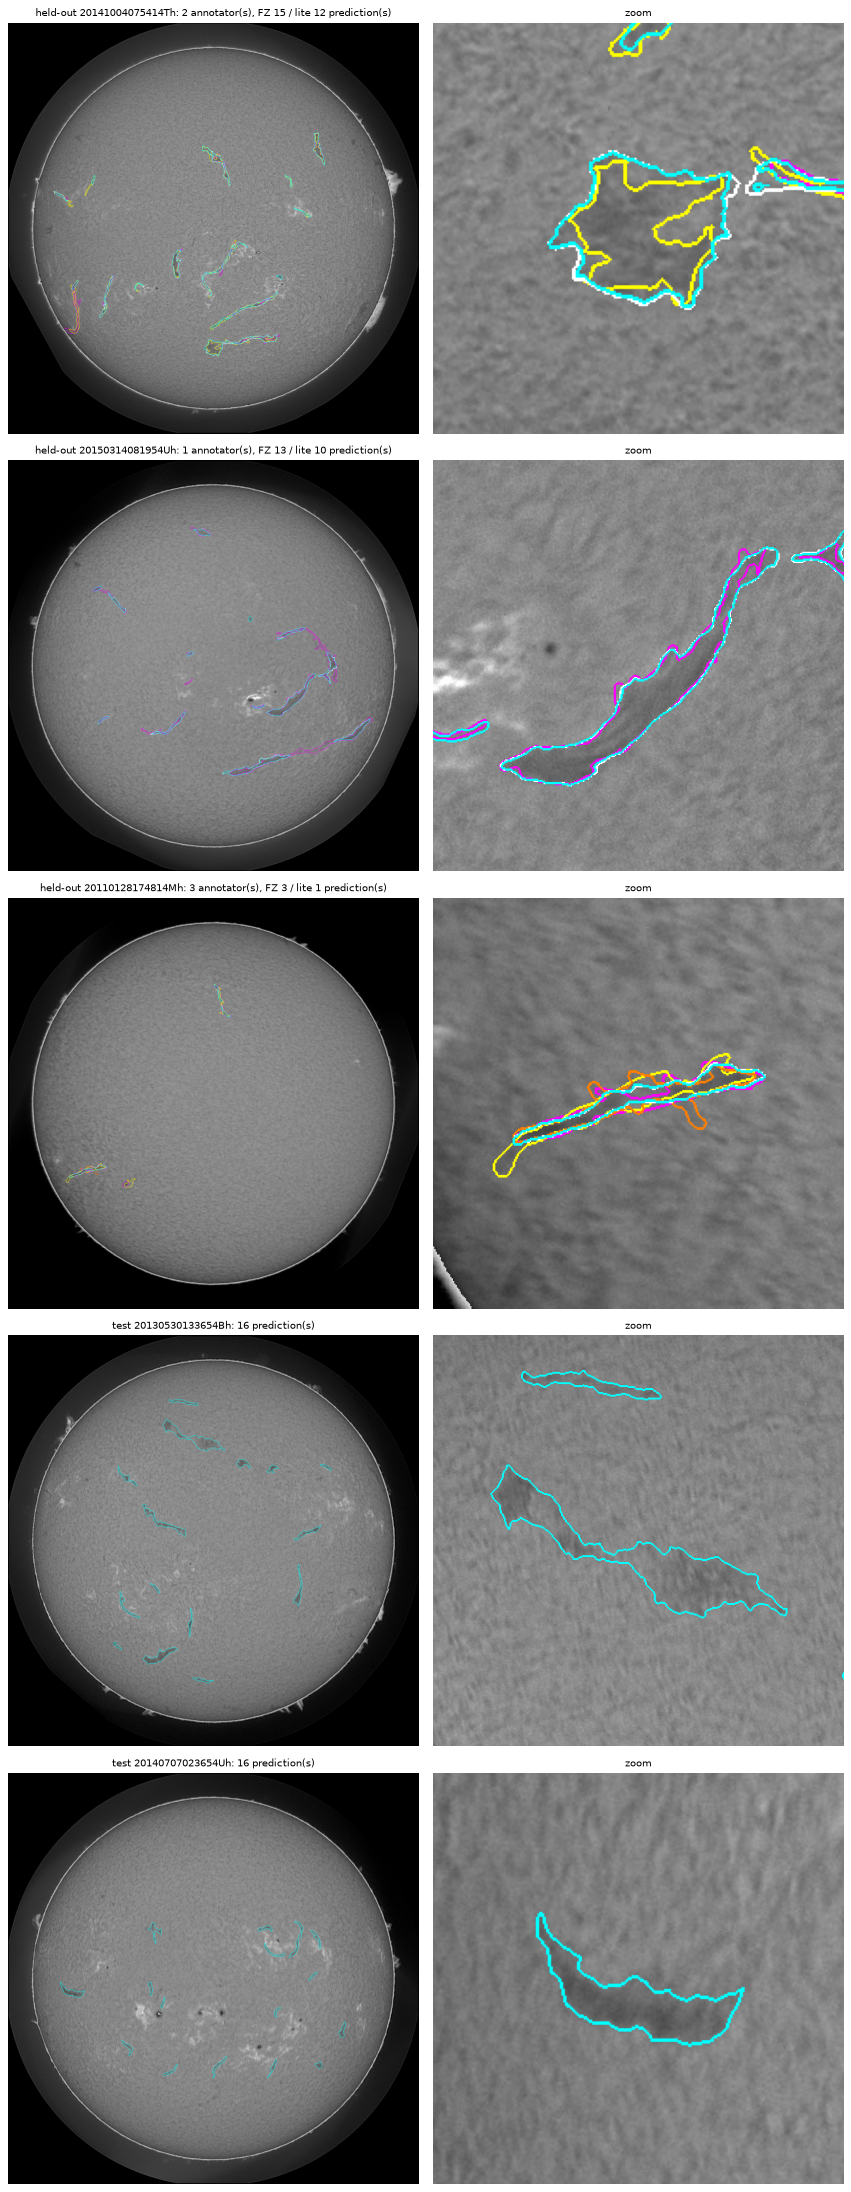

In [10]:
def rles_to_labels(rles):
    lab = np.zeros((2048, 2048), np.int32)
    for i, r in enumerate(rles, 1):
        lab[cm.decode({'size': [2048, 2048], 'counts': r.encode() if isinstance(r, str) else r}).astype(bool)] = i
    return lab

def zoom_box(lab, pad=60):
    if lab.max() == 0:
        return (slice(512, 1536), slice(512, 1536))
    big = np.argmax(np.bincount(lab.ravel())[1:])+1
    ys, xs = np.nonzero(lab == big)
    cy, cx, h = (ys.min()+ys.max())//2, (xs.min()+xs.max())//2, max(np.ptp(ys), np.ptp(xs))//2+pad
    return (slice(max(cy-h, 0), cy+h), slice(max(cx-h, 0), cx+h))

colours = [(1, 0, 1), (1, 1, 0), (1, .5, 0), (0, 1, 0)]
gain = sorted(held, key=lambda k: len(held_frames['lite'][k]['rles'])-len(held_frames['FZ'][k]['rles']))
show = gain[:3]
fig, ax = plt.subplots(len(show)+2, 2, figsize=(11, 5.5*(len(show)+2)))
for row, k in enumerate(show):
    g = read_gray(train_paths[k]); fz = rles_to_labels(held_frames['FZ'][k]['rles']); lite = rles_to_labels(held_frames['lite'][k]['rles'])
    layers = [(rles_to_labels([r['counts'] for r in rl]), colours[i % 4]) for i, (_, rl) in enumerate(gt[k])] + [(lite, (1, 1, 1)), (fz, (0, 1, 1))]
    viz.overlay(g, layers, ax[row, 0], f'held-out {k}: {len(gt[k])} annotator(s), FZ {fz.max()} / lite {lite.max()} prediction(s)')
    viz.overlay(g, layers, ax[row, 1], 'zoom', crop=zoom_box(fz))
for row, k in enumerate(sorted(frames, key=lambda k: -len(frames[k]['rles']))[:2], len(show)):
    g = read_gray(test_paths[k]); pred = rles_to_labels(frames[k]['rles'])
    viz.overlay(g, [(pred, (0, 1, 1))], ax[row, 0], f'test {k}: {pred.max()} prediction(s)')
    viz.overlay(g, [(pred, (0, 1, 1))], ax[row, 1], 'zoom', crop=zoom_box(pred))
plt.tight_layout(); plt.show()

## Notes

- **Weights.** The U-Nets are fp32 safetensors shards (each < 95 MB). The crop CNNs store their
  conv/linear tensors in bf16, which is exactly what they compute with under bf16 autocast. The GBMs
  are gzip pickles. Every model is verified against `weights/manifest.json` when loaded.
- **Data rules.** Training used only the official training annotations: no external labels and no
  other GONG frames. Inference reads nothing but the test image itself.
- **Runtime.** Almost all CPU time goes to the networks: about 104 s per frame in lite mode, and
  about 238 s in FZ mode, where the five specialists at 2048² add about 27 s each. With a CUDA GPU
  (`inference.device: auto`) that part becomes small. Everything after the networks takes a few
  seconds per frame on a CPU.